# Used Car Price Prediction using Machine Learning

**Problem Statement:** Purani (second-hand) car ki details, jaise kitni purani hai, kitni chali hai, petrol/diesel, dekh kar uski **resale price predict karna**.

**Type:** Regression (output ek number hota hai)

**Dataset:** CarDekho Used Car Dataset (Kaggle/GitHub par free). Prices **Lakh rupees** mein dikhayi gayi hain.

## Step 1: Dataset load karna
Dataset **internet se apne aap load** ho jayega (CarDekho Used Car Dataset), kuch download ya upload nahi karna.
Agar kisi wajah se load na ho, to niche ek **Choose files** button aayega, tab Kaggle se download ki hui CarDekho CSV file upload kar dena.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

url = "https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv"
try:
    df = pd.read_csv(url)
    print("Dataset internet se load ho gaya")
except Exception:
    print("Internet se load nahi hua. Apni CSV file upload karo.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print("Rows aur columns:", df.shape)
df.head()

Dataset internet se load ho gaya
Rows aur columns: (15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


## Step 2: Data ko samajhna

In [2]:
print(df.info())
print()
print("Missing values:")
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB
None

Missing values:
Unnamed: 0           0
car_name        

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


## Step 3: Data Cleaning
- Column ke naam chhote (lowercase) aur ek jaise karna
- Price ko **Lakh** mein laana
- Car ka **saal** (year) seedha use karne ke bajay **car_age** (kitni purani hai) banana, ye model ke liye zyada useful hota hai
- Bahut zyada kilometre wali galat entries hatana
- Text columns (fuel, transmission) ko numbers mein badalna, kyunki model sirf numbers samajhta hai

In [3]:
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={"selling_price":"price", "kms_driven":"km_driven", "fuel_type":"fuel", "vehicle_age":"car_age", "transmission_type":"transmission"})

# Agar price rupees mein hai to Lakh mein badlo
if df["price"].max() > 1000:
    df["price"] = df["price"] / 100000

# Car ki umar (current year 2026)
if "year" in df.columns:
    df["car_age"] = 2026 - df["year"]

# Owner column text ho to number banao
if "owner" in df.columns and df["owner"].dtype == "object":
    owner_map = {"First Owner":1, "Second Owner":2, "Third Owner":3, "Fourth & Above Owner":4, "Test Drive Car":0}
    df["owner"] = df["owner"].map(owner_map).fillna(1)

# Sirf kaam ke columns rakho
keep = ["price","car_age","km_driven","fuel","seller_type","transmission","owner","present_price","mileage","engine","max_power","seats"]
df = df[[c for c in keep if c in df.columns]]

df = df.dropna()
df = df[df["km_driven"] < 500000]      # galat/extreme entries hatao
df = df[df["price"] < 100]              # 1 crore se upar ki bahut mehngi cars hatao

print("Cleaning ke baad shape:", df.shape)
df.head()

Cleaning ke baad shape: (15390, 10)


,price,car_age,km_driven,fuel,seller_type,transmission,mileage,engine,max_power,seats
0,1.20,9,120000,Petrol,Individual,Manual,19.70,796,46.30,5
1,5.50,5,20000,Petrol,Individual,Manual,18.90,1197,82.00,5
2,2.15,11,60000,Petrol,Individual,Manual,17.00,1197,80.00,5
3,2.26,9,37000,Petrol,Individual,Manual,20.92,998,67.10,5
4,5.70,6,30000,Diesel,Dealer,Manual,22.77,1498,98.59,5


## Step 4: Visualization (Graphs)

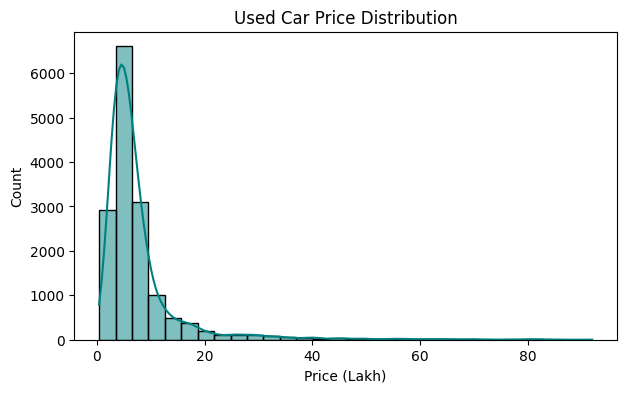

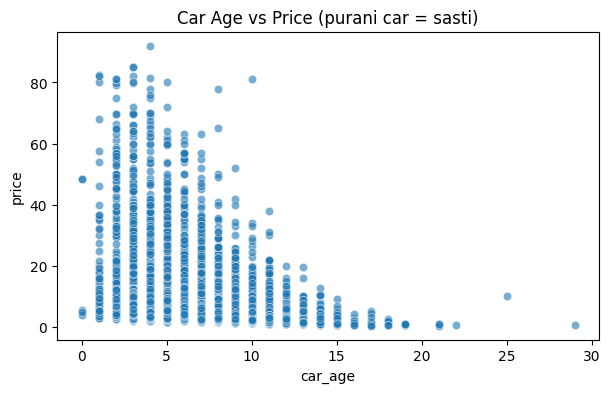

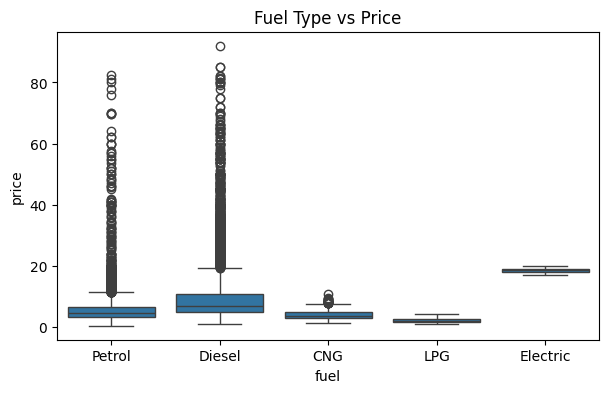

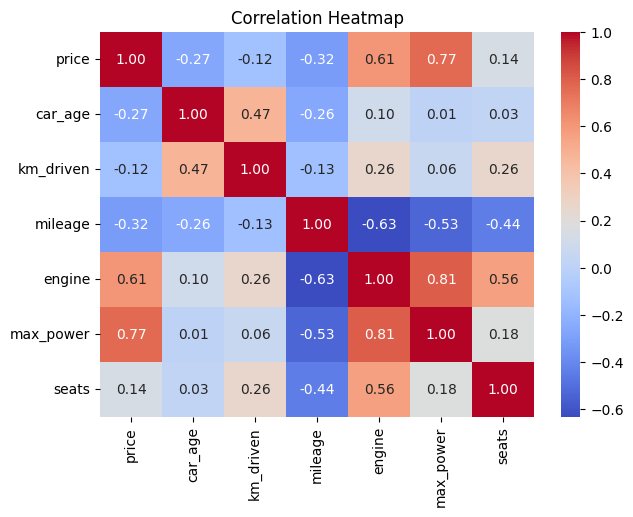

In [4]:
# Graph 1: Price ka distribution
plt.figure(figsize=(7,4))
sns.histplot(df["price"], bins=30, kde=True, color="teal")
plt.title("Used Car Price Distribution")
plt.xlabel("Price (Lakh)")
plt.show()

# Graph 2: Car ki umar vs price
plt.figure(figsize=(7,4))
sns.scatterplot(x="car_age", y="price", data=df, alpha=0.6)
plt.title("Car Age vs Price (purani car = sasti)")
plt.show()

# Graph 3: Fuel type ke hisaab se price
plt.figure(figsize=(7,4))
sns.boxplot(x="fuel", y="price", data=df)
plt.title("Fuel Type vs Price")
plt.show()

# Graph 4: Correlation heatmap
plt.figure(figsize=(7,5))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** Car jitni purani hoti hai, uski price utni kam hoti hai. Diesel aur automatic cars aam taur par zyada price par bikti hain.

## Step 5: Text ko numbers mein badalna aur Train-Test Split
Data ka **80% model ko sikhane** ke liye aur **20% test** karne ke liye, jo model ne pehle dekha nahi.

In [5]:
df_model = pd.get_dummies(df, drop_first=True)

X = df_model.drop("price", axis=1)   # input
y = df_model["price"]                # output

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12312, 13)
Testing data: (3078, 13)


## Step 6: 3 Models train karke compare karna
- **R² score**: 0 se 1 ke beech. Jitna 1 ke paas, utna model acha.
- **MAE**: model average kitna galat hai (Lakh mein). Jaise 0.8 matlab ₹80,000 ki average galti.

Linear Regression: R2 = 0.665 | MAE = 2.56 Lakh
Decision Tree: R2 = 0.913 | MAE = 1.22 Lakh
Random Forest: R2 = 0.945 | MAE = 0.99 Lakh


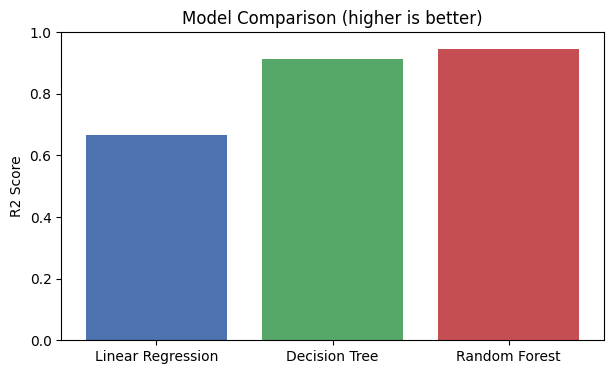

In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

r2_scores, mae_scores = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    r2_scores[name] = r2_score(y_test, pred)
    mae_scores[name] = mean_absolute_error(y_test, pred)
    print(f"{name}: R2 = {r2_scores[name]:.3f} | MAE = {mae_scores[name]:.2f} Lakh")

plt.figure(figsize=(7,4))
plt.bar(r2_scores.keys(), r2_scores.values(), color=["#4C72B0","#55A868","#C44E52"])
plt.ylabel("R2 Score")
plt.title("Model Comparison (higher is better)")
plt.ylim(0,1)
plt.show()

## Step 7: Best model ka result (Actual vs Predicted)

Best Model: Random Forest
R2 Score: 0.945
MAE: 0.99 Lakh (average galti Rs 98,601)


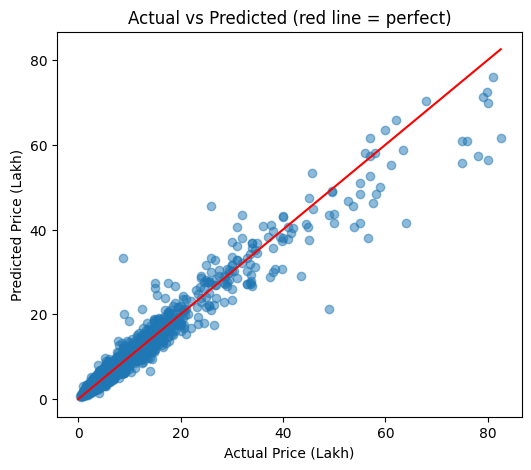

In [7]:
best_name = max(r2_scores, key=r2_scores.get)
best_model = models[best_name]
pred = best_model.predict(X_test)
best_mae = mae_scores[best_name]

print("Best Model:", best_name)
print(f"R2 Score: {r2_scores[best_name]:.3f}")
print(f"MAE: {best_mae:.2f} Lakh (average galti Rs {best_mae*100000:,.0f})")

plt.figure(figsize=(6,5))
plt.scatter(y_test, pred, alpha=0.5)
mx = max(y_test.max(), pred.max())
plt.plot([0,mx],[0,mx], color="red")
plt.xlabel("Actual Price (Lakh)")
plt.ylabel("Predicted Price (Lakh)")
plt.title("Actual vs Predicted (red line = perfect)")
plt.show()

## Step 8: Price par sabse zyada asar kis cheez ka padta hai?

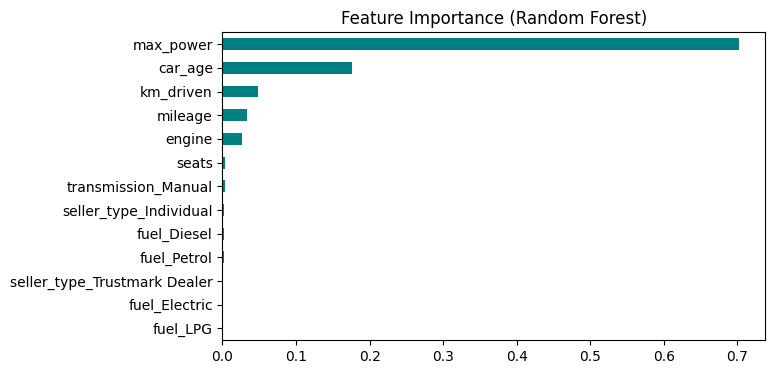

In [8]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(7,4), color="teal")
plt.title("Feature Importance (Random Forest)")
plt.show()

## Step 9: Nayi car ki price predict karna (price range ke saath)
Model ek price batata hai, aur hum **average galti (MAE)** ko plus-minus karke ek **price range** dikhate hain. Ye asli zindagi mein zyada useful hai.

In [9]:
# Yahan apni car ki details badal ke try karo
car = {"car_age": 5, "km_driven": 40000, "owner": 1,
       "fuel": "Petrol", "seller_type": "Dealer", "transmission": "Manual"}
# Agar dataset mein ye extra columns hain to unki sample values
extra = {"present_price": 8.0, "mileage": 18.0, "engine": 1200, "max_power": 85, "seats": 5}
for k, v in extra.items():
    if k in X.columns:
        car[k] = v

new_car = pd.get_dummies(pd.DataFrame([car]))
new_car = new_car.reindex(columns=X.columns, fill_value=0)

price = best_model.predict(new_car)[0]
print(f"Predicted Price: {price:.2f} Lakh")
print(f"Expected Range : {max(price-best_mae,0):.2f} to {price+best_mae:.2f} Lakh")

Predicted Price: 4.73 Lakh
Expected Range : 3.74 to 5.71 Lakh


## Conclusion
- Is project mein 3 models (Linear Regression, Decision Tree, Random Forest) banaye aur compare kiye gaye.
- **Random Forest** aam taur par sabse acha result deta hai.
- Car ki **umar, kilometre aur engine power** resale price ko sabse zyada affect karte hain.
- Model sirf ek estimate deta hai, asli price car ki condition aur market par bhi depend karti hai. Isliye hum price **range** dikhate hain.

## Future Scope
- Zyada bada aur latest data use karna (OLX, CarDekho website se)
- Car ki company/brand aur city ko bhi input banana
- Web app banana jahan user car ki details daal kar price dekh sake